# ZeRO on 32 virtual GPUs

Session 12 assignment: make 32 virtual GPUs, run a demo model on them, simulate ZeRO-1, ZeRO-2 and ZeRO-3, and show how memory and computation change.

**The virtual GPUs.** Each one is a separate CPU process, started with `torch.multiprocessing.spawn` and connected with `torch.distributed` over the gloo backend. They share no memory: anything one rank needs from another crosses a socket.

**The collectives are written by hand.** `zsim/comm.py` builds ring reduce-scatter, all-gather and all-reduce out of point-to-point `isend`/`irecv`. It never calls `dist.all_reduce`, so every byte that moves between ranks is counted by our own code.

**ZeRO is written by hand too.** `zsim/engine.py` holds each stage's training state in real tensors and registers each one in a ledger by its real storage size. Memory numbers below are read from those tensors, not computed from a formula. The course formulas are in `zsim/theory.py`, and each table puts the two side by side.

| | what every rank keeps per weight |
|---|---|
| DP | 2 B bf16 weight + 2 B bf16 grad + 4 B fp32 master + 8 B Adam m, v = **16 B** |
| ZeRO-1 | weight and grad in full; master and Adam split N ways → **4 + 12/N** |
| ZeRO-2 | weight in full; grad, master and Adam split → **2 + 14/N** |
| ZeRO-3 | everything split → **16/N** |


In [1]:
import json, math, os, platform, time
from pathlib import Path

import matplotlib.pyplot as plt
import torch

from zsim import STAGES, RunConfig, check_collectives, run
from zsim.model import unit_specs
from zsim.theory import (CARD_GIB, GIB, SPLIT, bucket_timeline, bytes_per_weight,
                         comm_in_P, gib_per_gpu, offload_split)

OUT = Path("submission_artifacts"); OUT.mkdir(exist_ok=True)
N = 32
LABEL = {"dp": "DP", "zero1": "ZeRO-1", "zero2": "ZeRO-2", "zero3": "ZeRO-3"}
COLOR = {"dp": "#6b7280", "zero1": "#2563eb", "zero2": "#059669", "zero3": "#d97706"}
NUM = {}          # every number the README quotes is written here
T0 = time.time()
print("torch", torch.__version__, "|", platform.platform(), "|", os.cpu_count(), "CPU cores")

torch 2.14.1 | macOS-27.0.1-arm64-arm-64bit-Mach-O | 10 CPU cores


## 1. The demo model

A character-level GPT trained on Tiny Shakespeare. It is split into **units**: the embeddings, one unit per transformer block, and the head. The unit is the granularity at which gradients are reduced and at which ZeRO-3 gathers and frees weights. Matrix multiplies run in bf16. LayerNorm, softmax and the loss run in fp32.

The global batch is fixed at 32 sequences of 64 characters. With N ranks, each rank gets 32/N of them. The optimizer therefore always sees the same batch, whatever N is, which is what makes runs at different N comparable.

In [2]:
cfg = RunConfig()
specs = unit_specs(cfg.model())
sizes = {u: sum(math.prod(s) for _, s in ps) for u, ps in specs}
n_params = sum(sizes.values())
padded = sum(-(-n // N) * N for n in sizes.values())
print(f"{n_params:,} weights in {len(specs)} units:", {u: f"{n:,}" for u, n in sizes.items()})
print(f"padded to multiples of N={N}: {padded:,} (+{padded - n_params} zeros, {100 * (padded - n_params) / n_params:.3f}%)")
NUM["model"] = dict(n_params=n_params, padded_at_32=padded, units=len(specs), d=cfg.d, n_layer=cfg.n_layer,
                    global_batch=cfg.global_batch, seq=cfg.seq)

212,480 weights in 6 units: {'embed': '8,256', 'block0': '49,984', 'block1': '49,984', 'block2': '49,984', 'block3': '49,984', 'head': '4,288'}
padded to multiples of N=32: 212,480 (+0 zeros, 0.000%)


## 2. The collectives, on 32 processes

Each rank fills a vector with its own random numbers. The ring then:
- reduce-scatters the vector, so rank r ends up owning chunk r of the sum;
- all-gathers those chunks back into the full sum;
- runs all-reduce as one call, which is just the two phases above.

The result is checked against gloo's own `all_reduce`.

In [3]:
col = check_collectives(world=N, numel=N * 4096)
b = col[0]
print("rank r owns chunk r of the sum      :", all(r["owns_chunk_rank"] for r in col))
print("reduce-scatter + all-gather == all-reduce, bit for bit:", all(r["rs_then_ag_equals_ar"] for r in col))
print("max |ring - gloo all_reduce|         :", max(r["max_abs_err_vs_gloo"] for r in col))
for tag in ("reduce_scatter", "all_gather", "all_reduce"):
    print(f"{tag:15s} sends {b['bytes'][tag] / b['input_bytes']:.4f} x its input per rank   (theory: {'2' if tag == 'all_reduce' else '1'} x (N-1)/N = {(2 if tag == 'all_reduce' else 1) * (N - 1) / N:.4f})")
NUM["collectives"] = dict(world=N, rs_ag_equals_ar=all(r["rs_then_ag_equals_ar"] for r in col),
                          max_err_vs_gloo=max(r["max_abs_err_vs_gloo"] for r in col),
                          bytes_over_input={k: v / b["input_bytes"] for k, v in b["bytes"].items()})

rank r owns chunk r of the sum      : True
reduce-scatter + all-gather == all-reduce, bit for bit: True
max |ring - gloo all_reduce|         : 7.62939453125e-06
reduce_scatter  sends 0.9688 x its input per rank   (theory: 1 x (N-1)/N = 0.9688)
all_gather      sends 0.9688 x its input per rank   (theory: 1 x (N-1)/N = 0.9688)
all_reduce      sends 1.9375 x its input per rank   (theory: 2 x (N-1)/N = 1.9375)


The difference from gloo is fp32 rounding. The ring adds the numbers in a different order, and floating-point addition is not associative. The equality on the second line is exact, which is the equivalence the course's Section 4 rests on: an all-reduce *is* a reduce-scatter followed by an all-gather, so the pair costs exactly what the whole costs.

## 3. All four arrangements on 32 virtual GPUs

The same model, the same data and the same seed are trained for 30 steps under each arrangement.

In [4]:
main = {}
for st in STAGES:
    t = time.time()
    main[st] = run(stage=st, world=N, steps=30)
    print(f"{LABEL[st]:7s} {time.time() - t:5.1f}s  final loss {main[st]['ranks'][0]['losses'][-1]:.4f}  weights sha {main[st]['master_sha']}")

DP       14.4s  final loss 2.9154  weights sha 3fde834bf60ea999


ZeRO-1   14.6s  final loss 2.9154  weights sha 3fde834bf60ea999


ZeRO-2   15.7s  final loss 2.9154  weights sha 3fde834bf60ea999


ZeRO-3   19.3s  final loss 2.9154  weights sha 3fde834bf60ea999


### 3a. Memory per GPU, measured

Bytes are summed from the ledger of live tensors on each rank after the last step, then divided by the number of weights that rank serves. **Peak** is the largest total the ledger reached at any moment during a step. It includes transient buffers: ZeRO-2's full gradient for one unit before it is reduce-scattered, and ZeRO-3's gathered weights for the unit being computed.

In [5]:
cats = ["param_bf16", "grad_bf16", "master", "adam_m", "adam_v"]
rows = []
print(f"{'':8s}" + "".join(f"{c:>11s}" for c in cats) + f"{'total':>9s}{'formula':>9s}{'peak':>8s}{'same on all 32?':>17s}")
for st in STAGES:
    rk = main[st]["ranks"]
    r0, w = rk[0], rk[0]["padded"]
    per = [r0["persistent"].get(c, 0) / w for c in cats]
    tot = r0["persistent_total"] / w
    same = len({r["persistent_total"] for r in rk}) == 1
    print(f"{LABEL[st]:8s}" + "".join(f"{x:11.4f}" for x in per) + f"{tot:9.4f}{bytes_per_weight(st, N):9.4f}{r0['peak_total'] / w:8.3f}{str(same):>17s}")
    rows.append(dict(stage=st, per_cat=dict(zip(cats, per)), total=tot, formula=bytes_per_weight(st, N),
                     peak=r0["peak_total"] / w, identical_across_ranks=same,
                     activation_bytes=r0["activation_bytes"]))
NUM["memory_N32"] = rows
print("\nactivation bytes saved for backward, per rank:", {LABEL[s]: main[s]["ranks"][0]["activation_bytes"] for s in STAGES})

         param_bf16  grad_bf16     master     adam_m     adam_v    total  formula    peak  same on all 32?
DP           2.0000     2.0000     4.0000     4.0000     4.0000  16.0000  16.0000  16.000             True
ZeRO-1       2.0000     2.0000     0.1250     0.1250     0.1250   4.3750   4.3750   4.375             True
ZeRO-2       2.0000     0.0625     0.1250     0.1250     0.1250   2.4375   2.4375   2.908             True
ZeRO-3       0.0625     0.0625     0.1250     0.1250     0.1250   0.5000   0.5000   1.441             True

activation bytes saved for backward, per rank: {'DP': 1082628, 'ZeRO-1': 1082628, 'ZeRO-2': 1082628, 'ZeRO-3': 1082628}


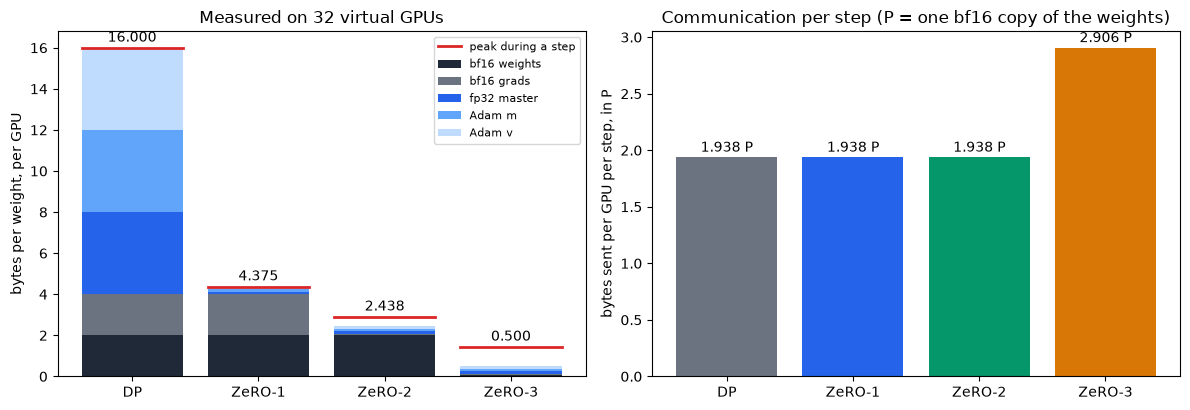

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
names = {"param_bf16": "bf16 weights", "grad_bf16": "bf16 grads", "master": "fp32 master", "adam_m": "Adam m", "adam_v": "Adam v"}
shade = ["#1f2937", "#6b7280", "#2563eb", "#60a5fa", "#bfdbfe"]
for i, r in enumerate(rows):
    bottom = 0
    for c, col_ in zip(cats, shade):
        ax[0].bar(i, r["per_cat"][c], bottom=bottom, color=col_, label=names[c] if i == 0 else None)
        bottom += r["per_cat"][c]
    ax[0].plot([i - .4, i + .4], [r["peak"]] * 2, color="#dc2626", lw=2, label="peak during a step" if i == 0 else None)
    ax[0].text(i, max(r["total"], r["peak"]) + .3, f"{r['total']:.3f}", ha="center")
ax[0].set_xticks(range(4), [LABEL[s] for s in STAGES]); ax[0].set_ylabel("bytes per weight, per GPU")
ax[0].set_title(f"Measured on {N} virtual GPUs"); ax[0].legend(fontsize=8)
sent = {s: sum(main[s]["ranks"][0]["bytes_sent"].values()) / (2 * main[s]["ranks"][0]["padded"]) for s in STAGES}
ax[1].bar(range(4), [sent[s] for s in STAGES], color=[COLOR[s] for s in STAGES])
for i, s in enumerate(STAGES):
    ax[1].text(i, sent[s] + .05, f"{sent[s]:.3f} P", ha="center")
ax[1].set_xticks(range(4), [LABEL[s] for s in STAGES]); ax[1].set_ylabel("bytes sent per GPU per step, in P")
ax[1].set_title("Communication per step (P = one bf16 copy of the weights)")
plt.tight_layout(); plt.savefig(OUT / "memory_and_comm_N32.png", dpi=130); plt.show()

### 3b. Communication per step, measured

Each rank counts the bytes it sends, broken down by which collective sent them. P is one bf16 copy of the weights, 2 bytes per weight.

In [7]:
comm_rows = []
for st in STAGES:
    r0 = main[st]["ranks"][0]; P = 2 * r0["padded"]
    parts = {k: v / P for k, v in r0["bytes_sent"].items()}
    tot = sum(parts.values())
    print(f"{LABEL[st]:7s} {tot:.4f} P  (formula {comm_in_P(st, N):.4f} P)   " + ", ".join(f"{k} {v:.4f}" for k, v in parts.items()))
    comm_rows.append(dict(stage=st, total_P=tot, formula_P=comm_in_P(st, N), parts=parts))
NUM["comm_N32"] = comm_rows

DP      1.9375 P  (formula 1.9375 P)   grad_all_reduce 1.9375
ZeRO-1  1.9375 P  (formula 1.9375 P)   grad_reduce_scatter 0.9688, param_all_gather_update 0.9688
ZeRO-2  1.9375 P  (formula 1.9375 P)   grad_reduce_scatter 0.9688, param_all_gather_update 0.9688
ZeRO-3  2.9062 P  (formula 2.9062 P)   param_all_gather_fwd 0.9688, param_all_gather_bwd 0.9688, grad_reduce_scatter 0.9688


With N = 32, (N-1)/N = 0.969. So:
- DP, ZeRO-1 and ZeRO-2 each send 1.94P per rank, which is the course's "2P".
- ZeRO-3 sends 2.91P, the course's "3P".

DP sends it all as one all-reduce. ZeRO-1 and ZeRO-2 send the same two halves, but split differently. They reduce-scatter the gradients, so each rank owns 1/N of the averaged gradient. They update that slice, then all-gather the updated weights. The volume is the same as DP's. What changes is what is kept between the two phases.

ZeRO-3 adds one more all-gather of the weights, because they are no longer stored anywhere in full. In fact it gathers them twice, once in the forward pass and once in the backward pass. In exchange, it drops the post-update all-gather, so the net change is one extra phase.

## 4. Same arithmetic, same answer

ZeRO only changes where state is stored, not what is computed. The strongest test of that claim is whether the four runs finish with identical bits.

In [8]:
shas = {LABEL[s]: main[s]["master_sha"] for s in STAGES}
print("sha256 of the final fp32 weights:", shas)
print("all four identical:", len(set(shas.values())) == 1)
ref = main["dp"]["master"]
for s in STAGES[1:]:
    print(f"max |w_{s} - w_dp| =", (main[s]["master"] - ref).abs().max().item())
NUM["bit_identical_bf16_N32"] = len(set(shas.values())) == 1

sha256 of the final fp32 weights: {'DP': '3fde834bf60ea999', 'ZeRO-1': '3fde834bf60ea999', 'ZeRO-2': '3fde834bf60ea999', 'ZeRO-3': '3fde834bf60ea999'}
all four identical: True
max |w_zero1 - w_dp| = 0.0
max |w_zero2 - w_dp| = 0.0
max |w_zero3 - w_dp| = 0.0


They are identical for two reasons:
- **The ring fixes the order of addition.** Chunk c of a reduce-scatter always starts on rank c+1 and always finishes on rank c. DP's all-reduce and ZeRO's reduce-scatter therefore add every gradient element in the same order.
- **Adam is elementwise.** `zsim.engine.adam_` uses one IEEE operation per line, with no fused multiply-add. Updating a 1/N slice therefore produces exactly the bits that updating the whole vector produces for that slice.

**Data parallelism against one GPU with the whole batch.** The course says DP is "mathematically identical to a single-GPU run on a batch eight times larger". In bf16 that is true of the maths but not of the bits. Each ring hop rounds a partial sum back to bf16. Adam then divides by √v, so gradients near zero that differ only in rounding still get full-size steps. Below, the same comparison runs in fp32, where only addition order differs.

fp32: DP and ZeRO-3 on 32 ranks bit-identical: True
|loss(32 ranks) - loss(1 process, same 32-sequence batch)| over 30 steps:
  fp32: mean 1.5e-05  max 1.8e-04  final 5.0e-06
  bf16: mean 2.6e-02  max 2.5e-01  final 3.0e-02


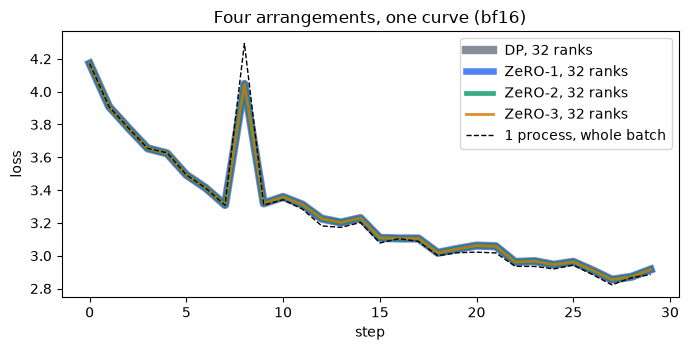

In [9]:
fp = {}
for name, kw in [("dp_N32", dict(stage="dp", world=N)), ("zero3_N32", dict(stage="zero3", world=N)), ("dp_N1", dict(stage="dp", world=1))]:
    fp[name] = run(steps=30, precision="fp32", **kw)
bf_ref = run(stage="dp", world=1, steps=30)
def gap(x, y):
    d = [abs(a - b) for a, b in zip(x["ranks"][0]["losses"], y["ranks"][0]["losses"])]
    return dict(mean=sum(d) / len(d), max=max(d), final=d[-1])
g_fp, g_bf = gap(fp["dp_N32"], fp["dp_N1"]), gap(main["dp"], bf_ref)
print("fp32: DP and ZeRO-3 on 32 ranks bit-identical:", fp["dp_N32"]["master_sha"] == fp["zero3_N32"]["master_sha"])
print("|loss(32 ranks) - loss(1 process, same 32-sequence batch)| over 30 steps:")
print(f"  fp32: mean {g_fp['mean']:.1e}  max {g_fp['max']:.1e}  final {g_fp['final']:.1e}")
print(f"  bf16: mean {g_bf['mean']:.1e}  max {g_bf['max']:.1e}  final {g_bf['final']:.1e}")
NUM["dp_vs_single"] = dict(fp32=g_fp, bf16=g_bf, fp32_dp_eq_zero3=fp["dp_N32"]["master_sha"] == fp["zero3_N32"]["master_sha"])

fig, ax = plt.subplots(figsize=(7, 3.6))
for s in STAGES:
    ax.plot(main[s]["ranks"][0]["losses"], color=COLOR[s], lw=6 - 1.3 * STAGES.index(s), alpha=.8, label=f"{LABEL[s]}, 32 ranks")
ax.plot(bf_ref["ranks"][0]["losses"], "k--", lw=1, label="1 process, whole batch")
ax.set_xlabel("step"); ax.set_ylabel("loss"); ax.legend(); ax.set_title("Four arrangements, one curve (bf16)")
plt.tight_layout(); plt.savefig(OUT / "loss_curves.png", dpi=130); plt.show()

In fp32 the 32-rank run follows the single process to within about 1e-5 on average. The only difference is the order of addition. In bf16 the gap is about a thousand times larger. The next cell asks how much of that comes from summing gradients in bf16 on the wire.

### 4a. Does the number of ranks change the answer in bf16?

Below, DP and ZeRO-2 are run at N = 1, 4 and 32, first with gradients summed in bf16 (as above) and then with gradients summed in fp32 (`reduce_dtype="fp32"`). The weights and the compute stay bf16 in both. A full-fp32 single process is included as the reference.

In [10]:
rd = {}
for n in (1, 4, 32):
    for red in ("same", "fp32"):
        r = run(stage="dp", world=n, steps=30, reduce_dtype=red)
        z = run(stage="zero2", world=n, steps=30, reduce_dtype=red)
        P = 2 * r["ranks"][0]["padded"]
        tail = sum(r["ranks"][0]["losses"][-10:]) / 10
        rd[(n, red)] = dict(tail_loss=tail, dp_eq_zero2=r["master_sha"] == z["master_sha"],
                            dp_sent_P=sum(r["ranks"][0]["bytes_sent"].values()) / P,
                            zero2_sent_P=sum(z["ranks"][0]["bytes_sent"].values()) / P,
                            zero2_bytes_per_weight=z["ranks"][0]["persistent_total"] / z["ranks"][0]["padded"])
ref_fp32 = sum(fp["dp_N1"]["ranks"][0]["losses"][-10:]) / 10
for v in rd.values():
    v["gap_to_fp32"] = abs(v["tail_loss"] - ref_fp32)
print(f"full fp32, 1 process: mean loss over steps 21-30 = {ref_fp32:.4f}\n")
print(f"{'N':>3s} {'grad sum':>9s} {'loss 21-30':>11s} {'|gap| to fp32':>14s} {'DP==ZeRO-2':>11s} {'DP sends':>9s} {'ZeRO-2 sends':>13s} {'ZeRO-2 B/w':>11s}")
for (n, red), v in rd.items():
    print(f"{n:3d} {'bf16' if red == 'same' else 'fp32':>9s} {v['tail_loss']:11.4f} {v['gap_to_fp32']:14.4f} {str(v['dp_eq_zero2']):>11s} {v['dp_sent_P']:8.3f}P {v['zero2_sent_P']:12.3f}P {v['zero2_bytes_per_weight']:11.4f}")
NUM["reduce_dtype"] = dict(full_fp32_N1_tail=ref_fp32, runs={f"N{n}_{'bf16' if r == 'same' else 'fp32'}": v for (n, r), v in rd.items()})

full fp32, 1 process: mean loss over steps 21-30 = 2.9287

  N  grad sum  loss 21-30  |gap| to fp32  DP==ZeRO-2  DP sends  ZeRO-2 sends  ZeRO-2 B/w
  1      bf16      2.9230         0.0057        True    0.000P        0.000P     16.0000
  1      fp32      2.9230         0.0057        True    0.000P        0.000P     18.0000
  4      bf16      2.9458         0.0171        True    1.500P        1.500P      5.5000
  4      fp32      2.9279         0.0008        True    3.000P        2.250P      6.0000
 32      bf16      2.9508         0.0220        True    1.938P        1.938P      2.4375
 32      fp32      2.9453         0.0165        True    3.875P        2.906P      2.5000


What this shows (the loss is averaged over steps 21 to 30 to smooth out batch noise; runs are deterministic, so these numbers reproduce):
- **With bf16 sums, the gap to the fp32 reference grows with N:** about 0.006 on one process, 0.017 on 4 ranks and 0.022 on 32. Every ring hop rounds a partial sum back to bf16's 8-bit mantissa, and more ranks means more hops.
- **Summing in fp32 closes almost all of the gap at N = 4, but only about a quarter of it at N = 32.** At 32 ranks each rank's gradient comes from a single sequence and is rounded to bf16 before it is sent, and that rounding stays.
- **DP and ZeRO-2 stay bit-identical in both modes,** so the drift comes from the precision of the sum, not from ZeRO.
- **fp32 sums double DP's traffic.** DP's all-reduce sends both phases in fp32. ZeRO-2 sends only its gradient reduce-scatter in fp32 and gathers the weights in bf16, so its cost rises by half rather than doubling, and its stored gradient slice is fp32 (2 + 16/N bytes per weight). That's one more practical reason to prefer ZeRO-2 over DP.


## 5. Memory as the number of GPUs grows

Each arrangement is run at N = 1, 2, 4, 8 and 16 (plus N = 32 from above), and each measured bytes-per-weight point is fitted to `a + b/N`.
- **a** is the state every rank keeps in full.
- **b** is the state that is split N ways.

The fit should recover the course's split from measurement alone: (16, 0), (4, 12), (2, 14) and (0, 16).

In [11]:
NS = [1, 2, 4, 8, 16, 32]
sweep = {s: {} for s in STAGES}
for n in NS[:-1]:
    for s in STAGES:
        r0 = run(stage=s, world=n, steps=3)["ranks"][0]
        sweep[s][n] = r0["persistent_total"] / r0["padded"]
for s in STAGES:
    sweep[s][N] = main[s]["ranks"][0]["persistent_total"] / main[s]["ranks"][0]["padded"]

fit = {}
for s in STAGES:
    X = torch.tensor([[1.0, 1.0 / n] for n in NS], dtype=torch.float64)
    y = torch.tensor([sweep[s][n] for n in NS], dtype=torch.float64)
    a, b = torch.linalg.lstsq(X, y.unsqueeze(1)).solution.flatten().tolist()
    fit[s] = (a, b)
    print(f"{LABEL[s]:7s} measured " + " ".join(f"{sweep[s][n]:7.3f}" for n in NS) + f"   fit a={a:6.3f} b={b:6.3f}   course {SPLIT[s]}")
NUM["sweep"] = dict(N=NS, bytes_per_weight={s: [sweep[s][n] for n in NS] for s in STAGES},
                    fit={s: dict(replicated=fit[s][0], sharded=fit[s][1]) for s in STAGES})

DP      measured  16.000  16.000  16.000  16.000  16.000  16.000   fit a=16.000 b= 0.000   course (16, 0)
ZeRO-1  measured  16.000  10.000   7.000   5.500   4.750   4.375   fit a= 4.000 b=12.000   course (4, 12)
ZeRO-2  measured  16.000   9.000   5.500   3.750   2.875   2.438   fit a= 2.000 b=14.000   course (2, 14)
ZeRO-3  measured  16.000   8.000   4.000   2.000   1.000   0.500   fit a=-0.000 b=16.000   course (0, 16)


### 5a. Scaling up to the course's 30B model

Here the fitted constants are applied to 30 billion weights and set against an 80 GB card, which holds 74.5 GiB. The aim is to reproduce the course's Section 7 table from constants measured on a model 150,000 times smaller.

                8       16       32       64   (GiB per GPU, from measured constants)
DP          447.0    447.0    447.0    447.0   course: 447.0 447.0 447.0 447.0
ZeRO-1      153.7    132.7    122.2    117.0   course: 153.7 132.7 122.2 117.0
ZeRO-2      104.8     80.3     68.1     62.0   course: 104.8 80.3 68.1 62.0
ZeRO-3       55.9     27.9     14.0      7.0   course: 55.9 27.9 14.0 7.0

an 80 GB card has 2.667 bytes per weight to give at 30B
smallest N that fits (training state only): {'DP': None, 'ZeRO-1': None, 'ZeRO-2': 22, 'ZeRO-3': 6}
model size at which 4 bytes/weight alone fills the card: 20.0 B weights


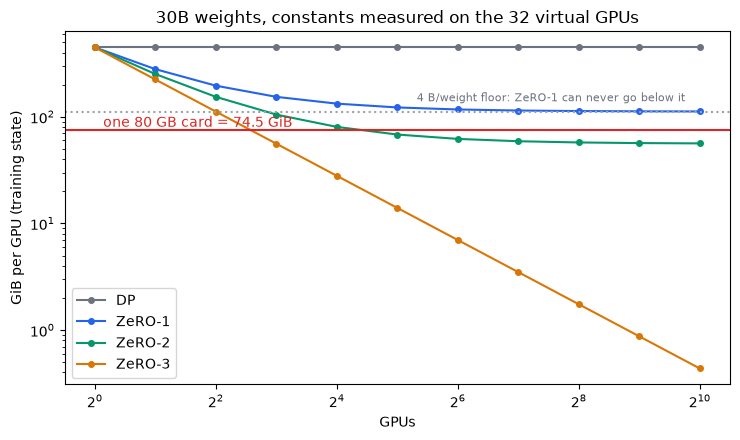

In [12]:
PSI = 30e9
def gib(s, n): a, b = fit[s]; return PSI * (a + b / n) / GIB
print(f"{'':8s}" + "".join(f"{n:>9d}" for n in (8, 16, 32, 64)) + "   (GiB per GPU, from measured constants)")
ladder = {}
for s in STAGES:
    ladder[s] = {n: gib(s, n) for n in (8, 16, 32, 64)}
    print(f"{LABEL[s]:8s}" + "".join(f"{ladder[s][n]:9.1f}" for n in (8, 16, 32, 64)) + "   course: " + " ".join(f"{gib_per_gpu(s, n):.1f}" for n in (8, 16, 32, 64)))
avail = 80e9 / PSI
min_n = {s: (None if SPLIT[s][0] >= avail else math.ceil(SPLIT[s][1] / (avail - SPLIT[s][0]))) for s in STAGES}
print(f"\nan 80 GB card has {avail:.3f} bytes per weight to give at 30B")
print("smallest N that fits (training state only):", {LABEL[s]: min_n[s] for s in STAGES})
print("model size at which 4 bytes/weight alone fills the card:", 80e9 / 4 / 1e9, "B weights")
NUM["ladder_30B"] = dict(gib=ladder, card_gib=CARD_GIB, min_gpus=min_n)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ns = [2 ** k for k in range(0, 11)]
for s in STAGES:
    ax.plot(ns, [gib(s, n) for n in ns], "o-", color=COLOR[s], label=LABEL[s], ms=4)
ax.axhline(CARD_GIB, color="#dc2626", lw=1.5); ax.text(1.1, CARD_GIB * 1.08, "one 80 GB card = 74.5 GiB", color="#dc2626")
ax.axhline(PSI * 4 / GIB, color="#9ca3af", ls=":"); ax.text(40, PSI * 4 / GIB * 1.25, "4 B/weight floor: ZeRO-1 can never go below it", color="#6b7280", fontsize=8)
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlabel("GPUs"); ax.set_ylabel("GiB per GPU (training state)")
ax.set_title("30B weights, constants measured on the 32 virtual GPUs"); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "memory_ladder_30B.png", dpi=130); plt.show()

## 6. How computation changes

Every rank runs the same forward and backward pass on its share of the batch, whatever the stage. What differs between stages is:
- how much of the optimizer step each rank does;
- where the communication sits in the step.

The times are averaged over steps 2 to 30 and over all 32 ranks. These are 32 processes on a laptop with 10 cores, so the absolute times are inflated. The comparisons between stages are the useful part.

          step ms     fwd     bwd    comm    Adam  Adam elems/rank  comm/compute
DP          277.5     5.7    17.3   252.6    0.90          212,480         10.14
ZeRO-1      289.4     6.3    19.0   263.2    0.42            6,640         10.03
ZeRO-2      305.2     4.5   185.2   287.6    0.53            6,640         16.37
ZeRO-3      420.1   133.1   286.7   402.0    0.24            6,640         22.22


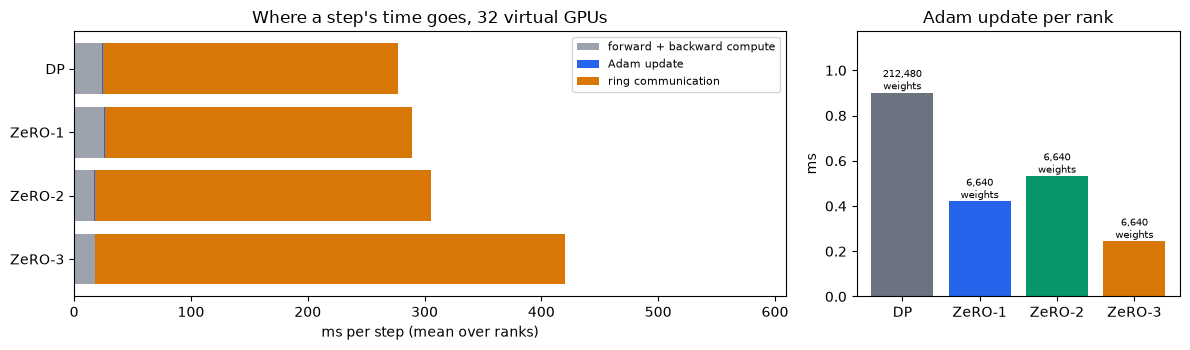

In [13]:
def avg(st, k): return sum(r["times"][k] for r in main[st]["ranks"]) / N
trows = []
print(f"{'':8s}{'step ms':>9s}{'fwd':>8s}{'bwd':>8s}{'comm':>8s}{'Adam':>8s}{'Adam elems/rank':>17s}{'comm/compute':>14s}")
for st in STAGES:
    r0 = main[st]["ranks"][0]
    adam_elems = r0["padded"] if st == "dp" else r0["padded"] // N
    step, comm, adam = avg(st, "step"), avg(st, "comm"), avg(st, "adam")
    trows.append(dict(stage=st, step_ms=1e3 * step, fwd_ms=1e3 * avg(st, "fwd"), bwd_ms=1e3 * avg(st, "bwd"),
                      comm_ms=1e3 * comm, adam_ms=1e3 * adam, adam_elems=adam_elems, comm_over_compute=comm / (step - comm)))
    t = trows[-1]
    print(f"{LABEL[st]:8s}{t['step_ms']:9.1f}{t['fwd_ms']:8.1f}{t['bwd_ms']:8.1f}{t['comm_ms']:8.1f}{t['adam_ms']:8.2f}{adam_elems:17,d}{t['comm_over_compute']:14.2f}")
NUM["time_N32"] = trows

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw=dict(width_ratios=[2.2, 1]))
for i, t in enumerate(trows):
    other = t["step_ms"] - t["comm_ms"] - t["adam_ms"]
    ax.barh(i, other, color="#9ca3af", label="forward + backward compute" if i == 0 else None)
    ax.barh(i, t["adam_ms"], left=other, color="#2563eb", label="Adam update" if i == 0 else None)
    ax.barh(i, t["comm_ms"], left=other + t["adam_ms"], color="#d97706", label="ring communication" if i == 0 else None)
ax.set_yticks(range(4), [LABEL[s] for s in STAGES]); ax.invert_yaxis(); ax.set_xlabel("ms per step (mean over ranks)")
ax.set_xlim(0, 1.45 * max(t["step_ms"] for t in trows))
ax.legend(fontsize=8, loc="upper right"); ax.set_title(f"Where a step's time goes, {N} virtual GPUs")
ax2.bar(range(4), [t["adam_ms"] for t in trows], color=[COLOR[s] for s in STAGES])
for i, t in enumerate(trows):
    ax2.text(i, t["adam_ms"], f"{t['adam_elems']:,}\nweights", ha="center", va="bottom", fontsize=7)
ax2.set_xticks(range(4), [LABEL[s] for s in STAGES]); ax2.set_ylabel("ms"); ax2.set_title("Adam update per rank")
ax2.set_ylim(0, 1.3 * max(t["adam_ms"] for t in trows))
plt.tight_layout(); plt.savefig(OUT / "step_time_N32.png", dpi=130); plt.show()

How to read the table:
- **Adam** runs on all the weights in DP and on 1/32 of them in every ZeRO stage. That's the computation ZeRO removes, along with the memory.
- **Communication** is the same volume for DP, ZeRO-1 and ZeRO-2. ZeRO-2 does its reduce-scatter inside the backward pass, unit by unit, which is why its `bwd` column grows and its after-backward work shrinks.
- **ZeRO-3** sends 1.5 times as much and puts part of it in the forward pass, because no unit can run until its weights have been gathered.
- **On this machine, communication dominates.** Each ring phase is 31 sequential hops through the kernel's socket stack, and the model is tiny, so the comm/compute column is far above the course's 34% for 64 H100s. That's the regime where the arrangement of the run matters most.

## 7. Offload: ZeRO-2 with the optimizer state in host memory

The fp32 master copy and the Adam state are 12 of the 16 bytes per weight, and each is touched once per step. Here they are moved to "host memory", and the update is done there. Each step then pays for two transfers over PCIe: the gradient slice goes to the host, and the updated bf16 weight slice comes back.

Every rank is a CPU process, so "device" and "host" are two separate ledgers rather than two physical memories. The bytes are measured, and the time is priced at the course's 60 GB/s.

In [14]:
off = run(stage="zero2", world=N, steps=3, offload=True)
r0 = off["ranks"][0]; w = r0["padded"]
exp = offload_split(N)
print(f"device {r0['persistent_total'] / w:.4f} B/weight (formula {exp['device']:.4f})   {r0['persistent']}")
print(f"host   {r0['host_total'] / w:.4f} B/weight (formula {exp['host']:.4f})")
print(f"PCIe   {r0['pcie_bytes'] / w:.4f} B/weight per step (formula {exp['pcie_per_step']:.4f})")
print("weights identical to plain ZeRO-2 after 3 steps:", off["master_sha"] == run(stage="zero2", world=N, steps=3)["master_sha"])
adam_rate = main["dp"]["ranks"][0]["padded"] / (avg("dp", "adam"))
o30 = {n: dict(device_gib=PSI * offload_split(n)["device"] / GIB, host_gib_per_gpu=PSI * offload_split(n)["host"] / GIB,
               pcie_s=PSI * offload_split(n)["pcie_per_step"] / 60e9) for n in (8, 32)}
for n, o in o30.items():
    print(f"30B on {n:2d} GPUs: device {o['device_gib']:.1f} GiB (card {CARD_GIB:.1f}), host {o['host_gib_per_gpu']:.1f} GiB per GPU "
          f"= {8 * o['host_gib_per_gpu']:.0f} GiB per 8-GPU node, PCIe {o['pcie_s'] * 1e3:.0f} ms per step")
print(f"Adam on one CPU core here: {adam_rate / 1e6:.0f} M weights/s, so {PSI / 8 / adam_rate:.0f} core-seconds per step per GPU's slice at 30B on 8 GPUs")
NUM["offload"] = dict(device=r0["persistent_total"] / w, host=r0["host_total"] / w, pcie=r0["pcie_bytes"] / w,
                      at_30B=o30, adam_weights_per_s_one_core=adam_rate)

device 2.0625 B/weight (formula 2.0625)   {'param_bf16': 424960, 'grad_bf16': 13280}
host   0.3750 B/weight (formula 0.3750)
PCIe   0.1250 B/weight per step (formula 0.1250)


weights identical to plain ZeRO-2 after 3 steps: True
30B on  8 GPUs: device 62.9 GiB (card 74.5), host 41.9 GiB per GPU = 335 GiB per 8-GPU node, PCIe 250 ms per step
30B on 32 GPUs: device 57.6 GiB (card 74.5), host 10.5 GiB per GPU = 84 GiB per 8-GPU node, PCIe 62 ms per step
Adam on one CPU core here: 236 M weights/s, so 16 core-seconds per step per GPU's slice at 30B on 8 GPUs


ZeRO-2 with offload fits 30B from **3** cards upward, because 2 + 2/N ≤ 2.667 bytes per weight. On 8 cards it leaves about 12 GiB per card for activations. Plain ZeRO-2 needs at least 22 cards (32 in powers of two). The PCIe traffic is small, because only 4/N bytes per weight cross it.

The real cost is the CPU doing Adam for 3.75 billion weights per GPU on every step. That's why the course calls offload a tool for a run whose binding constraint is GPU memory.

## 8. Gradient buckets and overlap

The demo model goes up to 12 transformer blocks here, matching the course widget's 12 layers, and runs DP on 8 ranks. Gradients are sent in buckets of 1, 2, 4, 7 or 14 units. Each bucket size is run twice:
- with overlap off, buckets are sent after backward;
- with overlap on, a communication thread sends each bucket while backward continues.

In [15]:
bk = {}
for k in (1, 2, 4, 7, 14):
    for ov in (False, True):
        r = run(stage="dp", world=8, steps=6, n_layer=12, bucket_units=k, overlap=ov)
        steps = [x["times"]["step"] for x in r["ranks"]]
        calls = r["ranks"][0]["calls"]["grad_all_reduce"] // 2
        bk[(k, ov)] = dict(step_ms=1e3 * max(steps), comm_ms=1e3 * sum(x["times"]["comm"] for x in r["ranks"]) / 8,
                           transfers=calls, sha=r["master_sha"], timeline=r["ranks"][0]["timeline"], bwd_end=r["ranks"][0]["bwd_end"])
        print(f"bucket {k:2d} units ({calls:2d} transfers)  overlap {str(ov):5s}  step {bk[(k, ov)]['step_ms']:6.1f} ms  comm {bk[(k, ov)]['comm_ms']:6.1f} ms")
print("overlap on/off give identical weights at every bucket size:", all(bk[(k, False)]["sha"] == bk[(k, True)]["sha"] for k in (1, 2, 4, 7, 14)))
# fixed cost per transfer, from comm time vs number of transfers with overlap off
xs = torch.tensor([[1.0, bk[(k, False)]["transfers"]] for k in (1, 2, 4, 7, 14)], dtype=torch.float64)
ys = torch.tensor([bk[(k, False)]["comm_ms"] for k in (1, 2, 4, 7, 14)], dtype=torch.float64)
c0, alpha_ms = torch.linalg.lstsq(xs, ys.unsqueeze(1)).solution.flatten().tolist()
print(f"fit: comm_ms = {c0:.1f} + {alpha_ms:.2f} x transfers  ->  each all-reduce costs ~{alpha_ms:.1f} ms before any data moves")
NUM["buckets_N8"] = dict({f"k{k}_{'overlap' if ov else 'serial'}": dict(step_ms=v["step_ms"], comm_ms=v["comm_ms"], transfers=v["transfers"])
                          for (k, ov), v in bk.items()}, fixed_cost_ms=alpha_ms)

bucket  1 units (14 transfers)  overlap False  step  149.4 ms  comm   45.5 ms


bucket  1 units (14 transfers)  overlap True   step  149.1 ms  comm  108.4 ms


bucket  2 units ( 7 transfers)  overlap False  step  141.6 ms  comm   34.6 ms


bucket  2 units ( 7 transfers)  overlap True   step  122.5 ms  comm   69.7 ms


bucket  4 units ( 4 transfers)  overlap False  step  124.8 ms  comm   23.3 ms


bucket  4 units ( 4 transfers)  overlap True   step  128.5 ms  comm   58.8 ms


bucket  7 units ( 2 transfers)  overlap False  step  118.0 ms  comm   15.7 ms


bucket  7 units ( 2 transfers)  overlap True   step  111.8 ms  comm   25.3 ms


bucket 14 units ( 1 transfers)  overlap False  step  114.5 ms  comm   12.3 ms


bucket 14 units ( 1 transfers)  overlap True   step  114.0 ms  comm   11.9 ms
overlap on/off give identical weights at every bucket size: True
fit: comm_ms = 11.9 + 2.57 x transfers  ->  each all-reduce costs ~2.6 ms before any data moves


Two things are true in every run on this machine:
1. **Every transfer pays a fixed start cost.** The fit above puts it at a few milliseconds per all-reduce on 8 ranks: 14 sequential socket hops, before any meaningful data moves. Fewer, larger buckets pay it less often, so with overlap off, communication time falls steadily as the bucket grows. This is the course's "larger buckets pay the fixed cost less often".
2. **Overlap saves less here than it would on a GPU.** With overlap on, the measured communication time roughly doubles, because the communication thread is competing with the backward pass for the same CPU cores. On a GPU, NCCL moves data with copy engines while the compute units keep working. So turning overlap on changes the step time by only about 20 ms either way. Which bucket size is fastest overall changes from run to run, because these differences are about the same size as the timing noise from many processes sharing 10 cores.

To see the course's GPU picture, the same timeline is replayed below in the course's own numbers. The model has 12 layers and 120 GB of gradient traffic per step (2.40 s over InfiniBand), with 7.10 s (H100) or 3.12 s (B200) of compute per step. The backward pass is taken as 2/3 of compute. Each transfer pays a fixed start cost α plus its share of the bytes.

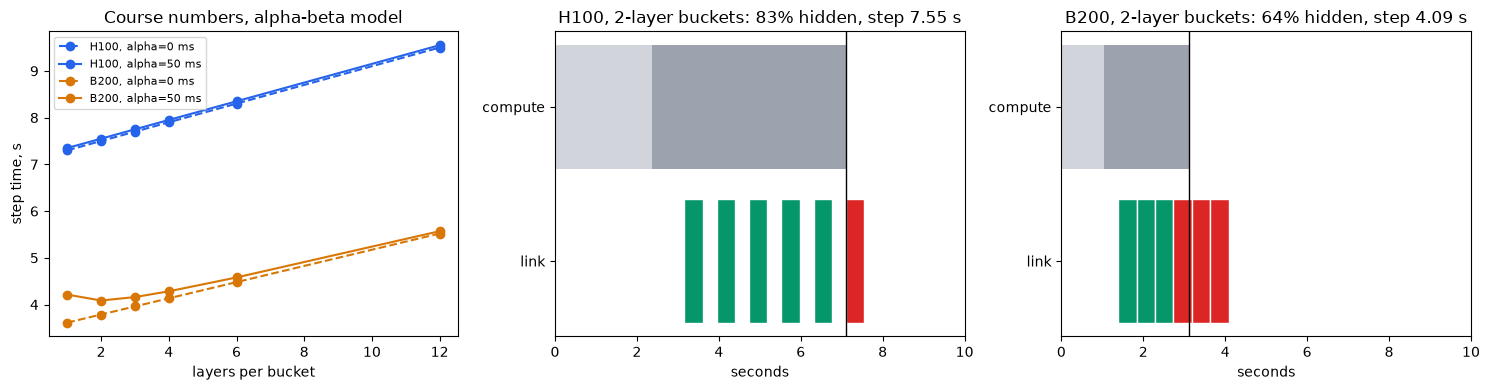

best bucket (layers): {'H100_alpha0.0': 1, 'H100_alpha0.05': 1, 'B200_alpha0.0': 1, 'B200_alpha0.05': 2}
B200 alpha=  0 ms -> best bucket 1 layers
B200 alpha= 10 ms -> best bucket 1 layers
B200 alpha= 20 ms -> best bucket 1 layers
B200 alpha= 30 ms -> best bucket 2 layers
B200 alpha= 40 ms -> best bucket 2 layers


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ks = [1, 2, 3, 4, 6, 12]
model_rows = {}
for card, comp in (("H100", 7.10), ("B200", 3.12)):
    for a in (0.0, 0.05):
        st = [bucket_timeline(comp, 2.40, bucket=k, alpha=a)["step"] for k in ks]
        model_rows[f"{card}_alpha{a}"] = dict(zip(ks, st))
        axes[0].plot(ks, st, "o-" if a else "o--", color="#2563eb" if card == "H100" else "#d97706",
                     label=f"{card}, alpha={a * 1e3:.0f} ms")
axes[0].set_xlabel("layers per bucket"); axes[0].set_ylabel("step time, s"); axes[0].set_title("Course numbers, alpha-beta model"); axes[0].legend(fontsize=8)
for ax, card, comp in ((axes[1], "H100", 7.10), (axes[2], "B200", 3.12)):
    tl = bucket_timeline(comp, 2.40, bucket=2, alpha=0.05)
    ax.barh(1, tl["fwd_end"], color="#d1d5db"); ax.barh(1, tl["bwd_end"] - tl["fwd_end"], left=tl["fwd_end"], color="#9ca3af")
    for s, e in tl["spans"]:
        ax.barh(0, e - s, left=s, color="#059669" if e <= tl["bwd_end"] else "#dc2626", edgecolor="white")
    ax.axvline(tl["bwd_end"], color="k", lw=1)
    ax.set_yticks([0, 1], ["link", "compute"]); ax.set_xlim(0, 10); ax.set_xlabel("seconds")
    ax.set_title(f"{card}, 2-layer buckets: {100 * tl['overlap_share']:.0f}% hidden, step {tl['step']:.2f} s")
plt.tight_layout(); plt.savefig(OUT / "buckets_model.png", dpi=130); plt.show()
best = {k: min(v, key=v.get) for k, v in model_rows.items()}
print("best bucket (layers):", best)
for a in (0.0, 0.01, 0.02, 0.03, 0.04):
    b200 = {k: bucket_timeline(3.12, 2.40, bucket=k, alpha=a)["step"] for k in ks}
    print(f"B200 alpha={a * 1e3:3.0f} ms -> best bucket {min(b200, key=b200.get)} layers")
NUM["buckets_model"] = dict(best=best, share_h100_k2=bucket_timeline(7.10, 2.40, bucket=2)["overlap_share"],
                            no_overlap_step=dict(H100=bucket_timeline(7.10, 2.40, bucket=12)["step"], B200=bucket_timeline(3.12, 2.40, bucket=12)["step"]))

The model reproduces the course's numbers:
- **9.50 s and 5.52 s with no hiding.** Those are the 12-layer bucket points, where everything is sent after backward.
- **On H100, the smallest bucket is best.**
- **83% hidden at 2 layers on H100.** The last of six buckets can only start once backward has finished, so 5/6 of the transfer time is hidden, whatever α is.

It also shows the condition behind the course's B200 result. The 2-layer optimum only appears when each transfer has a fixed cost of roughly 30 ms or more. At B200 speed, one layer's backward takes 0.17 s and one layer's gradients take 0.20 s to send, so the link can't keep up and transfers queue. Once they queue, merging buckets saves start-up costs and loses nothing. With α near zero, the smallest bucket still wins on B200.

So which bucket wins depends on whether the link is drained faster than backward refills it, and on how large α is. On this CPU, α is huge relative to the compute, which is why the biggest bucket wins in the measurement above.

In [17]:
NUM["runtime_s"] = time.time() - T0
NUM["machine"] = dict(torch=torch.__version__, platform=platform.platform(), cores=os.cpu_count())
(OUT / "s12_numbers.json").write_text(json.dumps(NUM, indent=1, default=str))
print(f"wrote {OUT / 's12_numbers.json'}; notebook ran in {NUM['runtime_s'] / 60:.1f} min")

wrote submission_artifacts/s12_numbers.json; notebook ran in 4.9 min
